# 02 · Telemetry channels

This is the only notebook that reads the raw ExaData telemetry. One pass over the raw parquet
files (19 channels × 6 months) produces two things:

* an **inventory** of every channel: rows, sampling cadence, whether it is a cumulative counter,
  share of zeros, whether it is constant;
* the raw **readings inside the 20-minute window** of every (job, node) of the reference cohort,
  saved in `data/raw_windows/<channel>.parquet`. Notebooks 04 and 05 use them.

The pass takes about 40–60 minutes and about 1 GB of memory the first time; each channel is saved
as soon as it is done and is not read again (delete `data/raw_windows/` to redo it).

In [1]:
import sys
sys.path.insert(0, "..")

import gc
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq

from tcc.config import CHANNELS, DATA, GROUPS, M100, MONTHS, RESULTS, WINDOW_S, source

RAW = DATA / "raw_windows"
RAW.mkdir(exist_ok=True)

## The windows

One window [t0, t0 + 20 min) per (job, node) of the reference cohort (69,096 jobs, before the GPU
filter, because notebook 04 measures the typical delivery of a node on all of them). Saved in
`data/windows.parquet` for notebook 04.

In [2]:
def node_windows(jobs):
    """One row per (job, node): the window [t0_ms, t1_ms) on that node."""
    w = jobs[["job_id", "t0_ms", "nodes"]].explode("nodes").rename(columns={"nodes": "node"})
    w["node"] = w["node"].astype("int16")
    w["t1_ms"] = w["t0_ms"] + WINDOW_S * 1000
    return w.reset_index(drop=True)

jobs = pd.read_parquet(DATA / "jobs.parquet")
windows = node_windows(jobs)
assert not windows.duplicated(["job_id", "node"]).any(), "a node appears twice in a job"
windows.to_parquet(DATA / "windows.parquet", index=False)
print(f"{len(jobs):,} jobs, {len(windows):,} (job, node) windows")

69,096 jobs, 259,839 (job, node) windows


## The pass over the raw files

An ExaData file holds the readings of one metric for one month: timestamp (ms, UTC), value and
node ("0" to "979"), in no particular order. For every file of a channel we

1. read it in batches of 15 million rows (about 0.5 GB of memory per batch);
2. sort each batch by (node, timestamp), using a single int64 key
   `key = node * 2**33 + (timestamp - first timestamp of the batch)`
   (2³³ ms is about 99 days, more than a month, so the two parts never overlap);
3. record inventory statistics: the interval between consecutive readings of the same node,
   whether the value rose or fell, zeros, minimum and maximum;
4. cut out the readings that fall in each window. Because the key is sorted, the readings of one
   window are one contiguous slice, found with two binary searches (`np.searchsorted`) for all
   windows at once.

Steps 3 and 4 share the same sorted batch, so each raw file is read only once.

In [3]:
SHIFT = 2 ** 33
BATCH_ROWS = 15_000_000
MAX_INTERVAL_S = 3600            # the interval histogram goes up to 1 h; longer gaps land in the last bin


def channel_files(channel):
    plugin = CHANNELS[channel]
    files = []
    for m in MONTHS:
        files += sorted((M100 / f"year_month={m}" / f"plugin={plugin}" / f"metric={channel}").glob("*.parquet"))
    return files


def sorted_batches(path, as_float64):
    """Yield (key, value, base) for each batch of a file, sorted by key."""
    pf = pq.ParquetFile(path, read_dictionary=["node"])
    for rb in pf.iter_batches(batch_size=BATCH_ROWS, columns=["timestamp", "value", "node"]):
        nodes = rb.column("node")                                    # dictionary-encoded strings
        node = np.asarray(pc.cast(nodes.dictionary, pa.int64()))[np.asarray(nodes.indices)]
        ts = rb.column("timestamp").cast(pa.int64()).to_numpy()
        value = rb.column("value").cast(pa.float64() if as_float64 else pa.float32()).to_numpy(zero_copy_only=False)
        del rb, nodes
        base = int(ts.min())
        assert ts.max() - base < SHIFT and node.min() >= 0
        key = node * SHIFT + (ts - base)
        del node, ts
        order = np.argsort(key, kind="stable")
        yield key[order], value[order], base
        del key, value, order
        gc.collect()


def batch_inventory(key, value):
    """Step 3: statistics of one sorted batch."""
    node = key // SHIFT
    same_node = node[1:] == node[:-1]                      # consecutive readings of the same node
    interval_s = np.diff(key)[same_node] // 1000
    change = np.diff(value.astype(np.float64))[same_node]
    return {
        "rows": len(value),
        "nodes": np.unique(node),
        "interval_hist": np.bincount(np.minimum(interval_s, MAX_INTERVAL_S), minlength=MAX_INTERVAL_S + 1),
        "rises": int((change > 0).sum()),
        "falls": int((change < 0).sum()),
        "zeros": int((value == 0).sum()),
        "vmin": float(np.nanmin(value)),
        "vmax": float(np.nanmax(value)),
    }


def extract_windows(key, value, base, w_node, w_t0, w_t1):
    """Step 4: readings with t0 <= ts < t1 for every window.  Returns (window index, ts, value)."""
    lo_t = np.clip(w_t0 - base, 0, SHIFT - 1)
    hi_t = np.clip(w_t1 - base, 0, SHIFT - 1)
    lo = np.searchsorted(key, w_node * SHIFT + lo_t, side="left")
    hi = np.searchsorted(key, w_node * SHIFT + hi_t, side="left")
    n = hi - lo                                            # readings in each window
    if n.sum() == 0:
        return np.empty(0, np.int64), np.empty(0, np.int64), np.empty(0, value.dtype)
    window = np.repeat(np.arange(len(lo)), n)
    pos = np.arange(n.sum()) + np.repeat(lo - (np.cumsum(n) - n), n)   # row index of each reading
    return window, key[pos] % SHIFT + base, value[pos]


def process_channel(channel, windows, out_path):
    """Inventory of every file of a channel, plus the readings inside every window.

    The readings are written to `out_path` as (job_id, node, ts, value).  Returns the inventory.
    """
    as_float64 = CHANNELS[channel] == "ganglia_pub"        # ganglia memory in KB exceeds float32 precision
    w_node = windows["node"].to_numpy(np.int64)
    w_t0 = windows["t0_ms"].to_numpy(np.int64)
    w_t1 = windows["t1_ms"].to_numpy(np.int64)
    inv, pieces = [], []
    for path in channel_files(channel):
        for key, value, base in sorted_batches(path, as_float64):
            inv.append(batch_inventory(key, value))
            t_max = int((key % SHIFT).max()) + base
            sel = np.where((w_t1 > base) & (w_t0 <= t_max))[0]          # windows that overlap this batch
            i, ts, v = extract_windows(key, value, base, w_node[sel], w_t0[sel], w_t1[sel])
            pieces.append(pd.DataFrame({"i": sel[i], "ts": ts, "value": v}))
            del key, value                                 # free the batch before the next one is read
            gc.collect()
    r = pd.concat(pieces, ignore_index=True).drop_duplicates(["i", "ts"])   # a timestamp repeated on a node
    r["job_id"] = windows["job_id"].to_numpy()[r["i"].to_numpy()]
    r["node"] = windows["node"].to_numpy()[r["i"].to_numpy()]
    r[["job_id", "node", "ts", "value"]].sort_values(["job_id", "node", "ts"]).to_parquet(out_path, index=False)
    return {
        "channel": channel,
        "files": len(channel_files(channel)),
        "rows": int(sum(b["rows"] for b in inv)),
        "nodes": int(len(np.unique(np.concatenate([b["nodes"] for b in inv])))),
        "interval_hist": np.sum([b["interval_hist"] for b in inv], axis=0).astype(int).tolist(),
        "rises": int(sum(b["rises"] for b in inv)),
        "falls": int(sum(b["falls"] for b in inv)),
        "zeros": int(sum(b["zeros"] for b in inv)),
        "vmin": float(min(b["vmin"] for b in inv)),
        "vmax": float(max(b["vmax"] for b in inv)),
        "window_readings": int(len(r)),
    }

Run it, one channel at a time. A channel already saved is skipped.

In [4]:
for c in CHANNELS:
    if (RAW / f"{c}.parquet").exists() and (RAW / f"{c}.json").exists():
        continue
    inv = process_channel(c, windows, RAW / f"{c}.parquet")
    (RAW / f"{c}.json").write_text(json.dumps(inv))
    print(f"  {c:15s} {inv['rows']:>13,} raw rows, {inv['window_readings']:>11,} in windows")
    gc.collect()

inventory = {c: json.loads((RAW / f"{c}.json").read_text()) for c in CHANNELS}
print(f"{len(inventory)} channels ready")

19 channels ready


### Check: the extraction equals a direct filter on the raw file

For 8 jobs that started between 10 and 20 July 2020 (5 single-node, 3 multi-node), the readings
saved for their windows must be exactly the rows that a plain `pyarrow` filter finds in the July
file: same timestamps, same values.

In [5]:
july = jobs[(jobs.start_time >= "2020-07-10") & (jobs.start_time < "2020-07-20")]
sample = pd.concat([july[july.num_nodes_alloc == 1].sample(5, random_state=1),
                    july[july.num_nodes_alloc > 1].sample(3, random_state=1)])
w = node_windows(sample)
for channel in ["gpu0_core_temp", "mem_free", "proc_run"]:
    f = M100 / "year_month=20-07" / f"plugin={CHANNELS[channel]}" / f"metric={channel}" / "a_0.parquet"
    direct = pq.read_table(f, filters=[("node", "in", [str(n) for n in w.node.unique()])]).to_pandas()
    direct["ts"] = direct.timestamp.values.astype("datetime64[ms]").astype("int64")
    direct["node"] = direct.node.astype(int)
    saved = pd.read_parquet(RAW / f"{channel}.parquet", filters=[("job_id", "in", sample.job_id.tolist())])
    for r in w.itertuples():
        exp = direct[(direct.node == r.node) & (direct.ts >= r.t0_ms) & (direct.ts < r.t1_ms)].sort_values("ts")
        got = saved[(saved.job_id == r.job_id) & (saved.node == r.node)].sort_values("ts")
        assert np.array_equal(exp.ts.values, got.ts.values), (channel, r.job_id, r.node)
        assert np.allclose(exp.value.values.astype(float), got.value.values.astype(float))
    print(f"ok  {channel}: {len(w)} windows identical to the direct filter")

ok  gpu0_core_temp: 41 windows identical to the direct filter


ok  mem_free: 41 windows identical to the direct filter


ok  proc_run: 41 windows identical to the direct filter


## Inventory

* **Cadence.** The nominal sampling period is the *modal* interval between consecutive readings
  of the same node (intervals of 0 s, repeated timestamps, and of 1 h or more, gaps, are
  ignored). The median interval is shown next to it.
* **Cumulative counter.** A counter only rises between consecutive readings of a node. A channel
  is called cumulative if ≥ 99 % of its changes are rises; it would then have to be differenced.
* **Constant.** A channel whose minimum equals its maximum carries no information.

In [6]:
rows = []
for c, inv in inventory.items():
    h = np.array(inv["interval_hist"], dtype=float)
    useful = h.copy()
    useful[0] = useful[-1] = 0
    cadence = int(np.argmax(useful))
    rises_share = inv["rises"] / (inv["rises"] + inv["falls"]) if inv["rises"] + inv["falls"] else np.nan
    rows.append({"channel": c, "source": source(c), "rows": inv["rows"], "nodes": inv["nodes"],
                 "cadence_s": cadence, "median_interval_s": int(np.searchsorted(np.cumsum(h), h.sum() / 2)),
                 "share_at_cadence": h[cadence] / h.sum(),
                 "rises_share": rises_share, "cumulative": rises_share >= 0.99,
                 "zero_share": inv["zeros"] / inv["rows"], "constant": inv["vmin"] == inv["vmax"],
                 "vmin": inv["vmin"], "vmax": inv["vmax"]})
inv = pd.DataFrame(rows).set_index("channel")
inv.to_csv(RESULTS / "channel_inventory.csv")
inv.style.format({"rows": "{:,}", "share_at_cadence": "{:.2f}", "rises_share": "{:.2f}",
                  "zero_share": "{:.4f}", "vmin": "{:.6g}", "vmax": "{:.6g}"})

,source,rows,nodes,cadence_s,median_interval_s,share_at_cadence,rises_share,cumulative,zero_share,constant,vmin,vmax
channel,,,,,,,,,,,,
mem_total,ganglia,"83,082,874",988,60,60,0.80,0.51,False,0.0000,False,1.62833e+08,3.29874e+08
mem_free,ganglia,"89,286,033",988,40,40,0.61,0.44,False,0.0000,False,128064,3.26524e+08
mem_cached,ganglia,"89,042,882",988,40,40,0.61,0.79,False,0.0000,False,42240,3.15473e+08
mem_buffers,ganglia,"88,935,453",988,40,40,0.61,0.65,False,0.0016,False,0,2.47238e+06
swap_free,ganglia,"88,939,965",988,40,40,0.61,0.97,False,0.0000,False,0,4.19424e+06
cpu_wio,ganglia,"64,199,224",988,90,90,0.58,0.50,False,0.9994,False,0,100
proc_run,ganglia,"48,836,447",988,80,80,0.61,0.50,False,0.3777,False,0,16433
load_one,ganglia,"70,092,294",988,90,90,0.51,0.44,False,0.1864,False,0,103330
gpu0_core_temp,IPMI,"671,016,844",980,20,20,0.98,0.51,False,0.0000,False,17,86


In [7]:
ipmi_rows = inv[(inv.source == "IPMI") & ~inv.constant].rows / 1e6
print(f"{len(inv)} channels read")
print(f"IPMI channels: median {ipmi_rows.median():.0f} million rows, largest {ipmi_rows.max():.0f} ({ipmi_rows.idxmax()})")
assert (inv.median_interval_s == inv.cadence_s).all()
print("the median interval equals the modal interval in every channel")

19 channels read
IPMI channels: median 671 million rows, largest 673 (fan0_0)
the median interval equals the modal interval in every channel


### Constant channels are excluded

The GPU power channels `gv100card0/3` are zero in every row.

In [8]:
const = inv[inv.constant]
print(const[["rows", "zero_share", "vmin", "vmax"]])
assert set(const.index) == {"gv100card0", "gv100card3"} and (const.zero_share == 1).all()
used = inv[~inv.constant]
print(f"channels used: {len(used)} ({(used.source == 'ganglia').sum()} ganglia, {(used.source == 'IPMI').sum()} IPMI)")

                 rows  zero_share  vmin  vmax
channel                                      
gv100card0  673343919         1.0   0.0   0.0
gv100card3  673343781         1.0   0.0   0.0
channels used: 17 (8 ganglia, 9 IPMI)


### Cadence

In [9]:
print(used.reset_index().groupby("cadence_s").channel.agg(", ".join).to_string())

cadence_s
20    gpu0_core_temp, gpu1_core_temp, gpu3_core_temp...
40         mem_free, mem_cached, mem_buffers, swap_free
60                                            mem_total
80                                             proc_run
90                                    cpu_wio, load_one


The intervals of four channels. IPMI (20 s) is regular. The ganglia 40 s channels often skip a
beat (80 s, 120 s): this is why notebook 04 measures the *typical* delivery of a node instead of
assuming the nominal one.

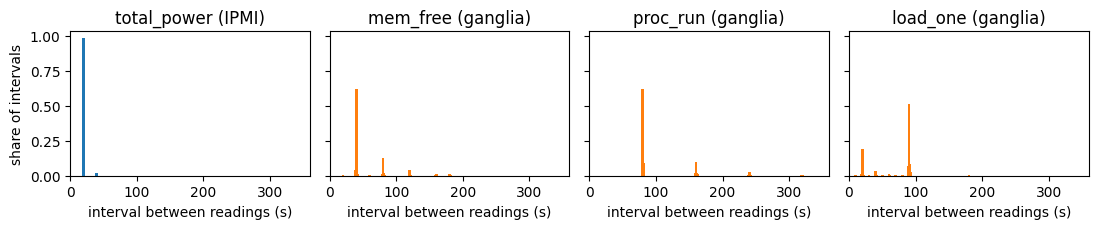

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.4), sharey=True)
for ax, c in zip(axes, ["total_power", "mem_free", "proc_run", "load_one"]):
    h = np.array(inventory[c]["interval_hist"][:361], dtype=float)
    ax.bar(np.arange(len(h)), h / h.sum(), width=4, color="C0" if source(c) == "IPMI" else "C1")
    ax.set_title(f"{c} ({source(c)})")
    ax.set_xlabel("interval between readings (s)")
    ax.set_xlim(0, 360)
axes[0].set_ylabel("share of intervals")
plt.tight_layout()

### No channel is cumulative

In [11]:
print(used[["rises_share", "cumulative"]].round(3).to_string())
print(f"cumulative channels: {used.cumulative.sum()}")

                rises_share  cumulative
channel                                
mem_total             0.515       False
mem_free              0.444       False
mem_cached            0.792       False
mem_buffers           0.652       False
swap_free             0.971       False
cpu_wio               0.497       False
proc_run              0.497       False
load_one              0.444       False
gpu0_core_temp        0.514       False
gpu1_core_temp        0.516       False
gpu3_core_temp        0.512       False
gpu4_core_temp        0.513       False
gpu0_mem_temp         0.506       False
gpu4_mem_temp         0.506       False
fan0_0                0.492       False
total_power           0.500       False
ambient               0.500       False
cumulative channels: 0


`swap_free` rises in most of its changes (swap is released slowly), but it changes rarely and is
a level (free swap), not a counter.

### `cpu_wio` is almost always zero

In [12]:
print(f'cpu_wio: {used.loc["cpu_wio", "zero_share"]:.2%} of readings are zero')

cpu_wio: 99.94% of readings are zero


## Metric groups

The ten groups built from the 17 channels ([`tcc/config.py`](../tcc/config.py), `GROUPS`). The cadence column lists
the cadences of the group's channels.

In [13]:
groups = pd.DataFrame([{"group": g, "source": source(chans[0]), "channels": ", ".join(chans),
                        "cadence_s": "/".join(str(c) for c in sorted({int(inv.loc[ch, "cadence_s"]) for ch in chans}))}
                       for g, chans in GROUPS.items()]).set_index("group")
groups.to_csv(RESULTS / "metric_groups.csv")
groups

,source,channels,cadence_s
group,,,
mem_active,ganglia,"mem_total, mem_free, mem_cached, mem_buffers",40/60
swap_free,ganglia,swap_free,40
cpu_wio,ganglia,cpu_wio,90
proc_run,ganglia,proc_run,80
load_one,ganglia,load_one,90
gpu_core_temp,IPMI,"gpu0_core_temp, gpu1_core_temp, gpu3_core_temp...",20
gpu_mem_temp,IPMI,"gpu0_mem_temp, gpu4_mem_temp",20
fan,IPMI,fan0_0,20
node_power,IPMI,total_power,20
